# Homework 4 - PHY 512

Élyse D'Aoust

261335942

## Question 1 - Time-independent Schrödinger equation

First, let's set up the matrices requires to solve this problem. Rewriting $\frac{d^2 \psi}{dx^2}$ as a second order finite difference, our time-independent Schrödinger equation becomes:

$$
-\frac{\hbar^2}{2m} \left( \frac{\psi_{i-1} - 2\psi_{i} + \psi_{i+1}}{(\Delta x)^2} \right) + V(x) \psi = E\psi
$$

Rewriting the three terms $\psi_{i-1}$, $2\psi_{i}$ and $\psi_{i+1}$ as a coefficient matrix $\mathbf{A}$ multiplied by $\psi$, we get:

$$
\rightarrow \quad -\frac{\hbar^2}{2m(\Delta x)^2} \left( \mathbf{A} \cdot \mathbf{\psi} \right) + V(x)\psi = E\psi
$$

with:

$$
A = \begin{bmatrix}
-2 & 1 & 0 & 0 & \dots & 0 \\
1 & -2 & 1 & 0 & \dots & 0 \\
0 & 1 & -2 & 1 & \dots & 0 \\
\vdots & \vdots & \ddots & \ddots & \ddots & \vdots \\
0 & 0 & \dots & 1 & -2 & 1 \\
0 & 0 & \dots & 0 & 1 & -2 
\end{bmatrix}
$$

Finally, we can rewrite our final equation as an eigenvalue problem, as follows (where $\psi$ is our eigenvector, and $E$ are our eigenvalues):

$$
\left( -\frac{\hbar^2}{2m(\Delta x)^2} \mathbf{A} + \mathbf{V}(x) \right) \mathbf{\psi} = E\psi
$$

We can therefore solve this eigenvalue problem using scipy.linalg.eigh, as shown in the code below. I will be using atomic units for this problem, by setting all fundamental physical constants to 1 to simplify the equation.

Ground state energy (atomic units): -0.6936391230135721


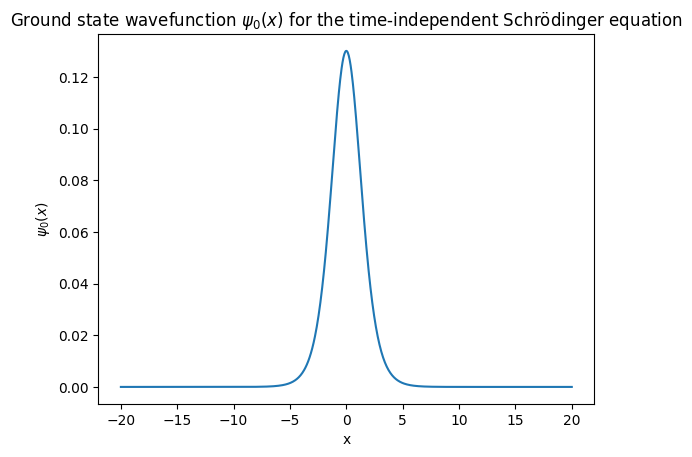

In [201]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

# Function to calulate the 1D potential
def V(x):
    V = -V0*np.exp(-(x/a)**2)
    return V

def solve_tise(x, h_bar, m, dx, n):
    # Set up matrix A (see explanation above for how we found this matrix)
    A = np.diag(2*((h_bar**2)/(2*m*(dx**2)))*np.ones(n), k=0) + \
        np.diag(-((h_bar**2)/(2*m*(dx**2)))*np.ones(n-1),k=-1) + \
        np.diag(-((h_bar**2)/(2*m*(dx**2)))*np.ones(n-1),k=1)

    # Set up diagonal matrix for the potential value at each x
    V_mat = np.diag(V(x)*np.ones(n), k=0)

    # Compute sum of the two matrices (will become the coefficient matrix for psi on the left hand side of the equation)
    AV = A + V_mat

    # Solve for the eigenvalues and eigenvectors
    E, psi = scipy.linalg.eigh(AV)
    return E, psi

# Define constants and variables (set all constants to 1, since we are using atomic units)
V0 = 1 # choose V0 = 1
h_bar = 1
m = 1

a = 2 # width of the potential well
n = 1000 # number of points on the grid
x = np.linspace(-20, 20, n)
dx = x[1] - x[0] # grid spacing

E, psi = solve_tise(x, h_bar, m, dx, n)

print("Ground state energy (atomic units):", E[0])

# Plotting
plt.plot(x, psi[:, 0])
#plt.plot(x, E)
plt.xlabel("x")
plt.ylabel(r"$\psi_0(x)$")
plt.title(r"Ground state wavefunction $\psi_{0}(x)$ for the time-independent Schrödinger equation")
plt.show()

Let's now vary the number of steps taken in order to obtain a numerical value for the energy of the ground state that is accurate to at least 1 part in 1000:

In [200]:
import numpy as np

# Define constants and variables (set all constants to 1, since we are using atomic units)
V0 = 1 # choose V0 = 1
h_bar = 1
m = 1

a = 2 # width of the potential well
n_vals = [250, 500, 750, 1000] # number of points on the grid

energies = [] # array to contain ground state energies

for n in n_vals:
    x = np.linspace(-20, 20, n)
    dx = x[1] - x[0] # grid spacing

    E, psi = solve_tise(x, h_bar, m, dx, n)
    energies.append(E[0]) # append ground state energy

# Estimate numerical error for ground state energy
for i, nval in enumerate(n_vals[1:]):
    rel_err = np.abs(energies[i+1]-energies[i])/np.abs(energies[i+1])
    print(f"Relative error for n={nval}:", rel_err)

Relative error for n=500: 0.0002694523475655165
Relative error for n=750: 4.961726019833921e-05
Relative error for n=1000: 1.7334350631067536e-05


Therefore, as shown above, the energy for the ground state is of approximately -0.693639 in atomic units (or Hartree), obtained with $n=1000$. From error calculations, this shows that the numerical error for this energy value is below the required tolerance of 1 part in 1000. For estimating the numerical error in the ground state energy, I calculated the energy for different number of steps/grid points, keeping the same bounds for x. Then, I compared ground state energies obtained with smaller numbers of steps with the following solution (using a larger number of steps), and found the relative difference by taking the absolute value of the difference of these two ground energies, divided by the absolute value of the ground state energy found with the larger number of steps of the two. As the number of steps increased, the relative error decreased, reaching approximately $1.73 \times 10^{-5}$ when comparing the energies for $n=750$ and $n=1000$.

## Question 2 - Separable wavefunctions

Part a)

Let's execute the matrix multiplication for $\mathbf{A} = \mathbf{USV^T}$ in order to prove that this can be written as the sum $\mathbf{A} = \sum_{\alpha}{s_{\alpha}\mathbf{u_{\alpha}}\mathbf{v^T_{\alpha}}}$. We have the following starting matrices:

$$
\mathbf{U} =
\begin{bmatrix}
| & | & | &  & | \\
u_1 & u_2 & u_3 & \cdots & u_n\\
| & | & | & & |
\end{bmatrix}
= 
\begin{bmatrix}
u_{11} & u_{21} & u_{31} & \cdots & u_{n1} \\
u_{12} & u_{22} & u_{32} &  \cdots & u_{n2} \\
u_{13} & u_{23} & u_{33} &  \cdots & u_{n3} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
u_{1n} & u_{2n} & u_{3n} &  \cdots & u_{nn} \\
\end{bmatrix}
$$

$$
\mathbf{V} = 
\begin{bmatrix}
| & | & | &  & | \\
v_1 & v_2 & v_3 & \cdots & v_n\\
| & | & | & & |
\end{bmatrix}
=
\begin{bmatrix}
v_{11} & v_{21} & v_{31} & \cdots & v_{n1} \\
v_{12} & v_{22} & v_{32} &  \cdots & v_{n2} \\
v_{13} & v_{23} & v_{33} &  \cdots & v_{n3} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
v_{1n} & v_{2n} & v_{3n} &  \cdots & v_{nn} \\
\end{bmatrix}
$$

$$
\rightarrow \quad \mathbf{V^T} =
\begin{bmatrix}
- & v_1^T & - \\
- & v_2^T & - \\
- & v_3^T & -
\end{bmatrix}
= 
\begin{bmatrix}
v_{11} & v_{12} & v_{13} & \cdots & v_{1n} \\
v_{21} & v_{22} & v_{23} &  \cdots & v_{2n} \\
v_{31} & v_{32} & v_{33} &  \cdots & v_{3n} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
v_{n1} & v_{n2} & v_{n3} &  \cdots & v_{nn} \\
\end{bmatrix}
$$

$$
\mathbf{S} = \begin{bmatrix}
s_{1} & 0 & 0 & \cdots & 0 \\
0 & s_{2} & 0 &  \cdots & 0 \\
0 & 0 & s_{3} &  \cdots & 0 \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
0 & 0 & 0 &  \cdots & s_{n} \\
\end{bmatrix}
$$

Let's now do the matrix multiplication. Let's start with multiplying $\mathbf{U}$ and $\mathbf{S}$:

$$
\mathbf{US} = 
\begin{bmatrix}
u_{11} & u_{21} & u_{31} & \cdots & u_{n1} \\
u_{12} & u_{22} & u_{32} &  \cdots & u_{n2} \\
u_{13} & u_{23} & u_{33} &  \cdots & u_{n3} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
u_{1n} & u_{2n} & u_{3n} &  \cdots & u_{nn} \\
\end{bmatrix}
\begin{bmatrix}
s_{1} & 0 & 0 & \cdots & 0 \\
0 & s_{2} & 0 &  \cdots & 0 \\
0 & 0 & s_{3} &  \cdots & 0 \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
0 & 0 & 0 &  \cdots & s_{n} \\
\end{bmatrix}
$$

$$
= 
\begin{bmatrix}
u_{11}s_1 & u_{21}s_2 & u_{31}s_3 & \cdots & u_{n1}s_n \\
u_{12}s_1 & u_{22}s_2 & u_{32}s_3 &  \cdots & u_{n2}s_n \\
u_{13}s_1 & u_{23}s_2 & u_{33}s_3 &  \cdots & u_{n3}s_n \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
u_{1n}s_1 & u_{2n}s_2 & u_{3n}s_3 &  \cdots & u_{nn}s_n \\
\end{bmatrix}
=
\begin{bmatrix}
| & | & | &  & | \\
u_1s_1 & u_2s_2 & u_3s_3 & \cdots & u_ns_n\\
| & | & | & & |
\end{bmatrix}
$$

Now, let's multiply the resulting matrix with $\mathbf{V^T}$:

$$
\mathbf{USV^T} =
\begin{bmatrix}
u_{11}s_1v_{11} + u_{21}s_2v_{21} + \cdots + u_{n1}s_nv_{n1} & u_{11}s_1v_{12} + u_{21}s_2v_{22} + \cdots + u_{n1}s_nv_{n2} & \cdots & u_{11}s_1v_{1n} + u_{21}s_2v_{2n} + \cdots + u_{n1}s_nv_{nn} \\
u_{12}s_1v_{11} + u_{22}s_2v_{21} + \cdots + u_{n2}s_nv_{n1} & u_{12}s_1v_{12} + u_{22}s_2v_{22} + \cdots + u_{n2}s_nv_{n2} & \cdots & u_{12}s_1v_{1n} + u_{22}s_2v_{2n} + \cdots + u_{n2}s_nv_{nn} \\
u_{13}s_1v_{11} + u_{23}s_2v_{21} + \cdots + u_{n3}s_nv_{n1} & u_{13}s_1v_{12} + u_{23}s_2v_{22} + \cdots + u_{n3}s_nv_{n2} & \cdots & u_{13}s_1v_{1n} + u_{23}s_2v_{2n} + \cdots + u_{n3}s_nv_{nn} \\
\vdots & \vdots & \ddots & \vdots \\
u_{1n}s_1v_{11} + u_{2n}s_2v_{21} + \cdots + u_{nn}s_nv_{n1} & u_{1n}s_1v_{12} + u_{2n}s_2v_{22} + \cdots + u_{nn}s_nv_{n2} & \cdots & u_{1n}s_1v_{1n} + u_{2n}s_2v_{2n} + \cdots + u_{nn}s_nv_{nn} \\
\end{bmatrix}
$$

We can write this as a sum of matrices, each having one of the singular values as coefficient, as follows:

$$
\mathbf{USV^T} = s_1
\begin{bmatrix}
u_{11}v_{11} & u_{11}v_{12} & u_{11}v_{13} & \cdots & u_{11}v_{1n} \\
u_{12}v_{11} & u_{12}v_{12} & u_{12}v_{13} & \cdots & u_{12}v_{1n} \\
u_{13}v_{11} & u_{13}v_{12} & u_{13}v_{13} & \cdots & u_{13}v_{1n} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
u_{1n}v_{11} & u_{1n}v_{12} & u_{1n}v_{13} & \cdots & u_{1n}v_{1n} \\
\end{bmatrix}
+ s_2
\begin{bmatrix}
u_{21}v_{21} & u_{21}v_{22} & u_{21}v_{23} & \cdots & u_{21}v_{2n} \\
u_{22}v_{21} & u_{22}v_{22} & u_{22}v_{23} & \cdots & u_{22}v_{2n} \\
u_{23}v_{21} & u_{23}v_{22} & u_{23}v_{23} & \cdots & u_{23}v_{2n} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
u_{2n}v_{21} & u_{2n}v_{22} & u_{2n}v_{23} & \cdots & u_{2n}v_{2n} \\
\end{bmatrix}
+ \cdots
+ s_n
\begin{bmatrix}
u_{n1}v_{n1} & u_{n1}v_{n2} & u_{n1}v_{n3} & \cdots & u_{n1}v_{nn} \\
u_{n2}v_{n1} & u_{n2}v_{n2} & u_{n2}v_{n3} & \cdots & u_{n2}v_{nn} \\
u_{n3}v_{n1} & u_{n3}v_{n2} & u_{n3}v_{n3} & \cdots & u_{n3}v_{nn} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
u_{nn}v_{n1} & u_{nn}v_{n2} & u_{nn}v_{n3} & \cdots & u_{nn}v_{nn} \\
\end{bmatrix}
$$

We can express each matrix in the sum above as a multiplication between the column vector $u_{\alpha}$ and row vector $v^T_{\alpha}$. Let's look at the first matrix in the sum as an example. We have:

$$
\mathbf{u_1v^T_1} = 
\begin{bmatrix}
u_{11} \\
u_{12} \\
u_{13} \\
\vdots \\
u_{1n} \\
\end{bmatrix}
\begin{bmatrix}
v_{11} & v_{12} & v_{13} & \cdots & v_{1n}
\end{bmatrix}
=
\begin{bmatrix}
u_{11}v_{11} & u_{11}v_{12} & u_{11}v_{13} & \cdots & u_{11}v_{1n} \\
u_{12}v_{11} & u_{12}v_{12} & u_{12}v_{13} & \cdots & u_{12}v_{1n} \\
u_{13}v_{11} & u_{13}v_{12} & u_{13}v_{13} & \cdots & u_{13}v_{1n} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
u_{1n}v_{11} & u_{1n}v_{12} & u_{1n}v_{13} & \cdots & u_{1n}v_{1n} \\
\end{bmatrix}
$$

Therefore, we can rewrite the sum as:

$$
\mathbf{USV^T} = s_1
\begin{bmatrix}
u_{11} \\
u_{12} \\
u_{13} \\
\vdots \\
u_{1n} \\
\end{bmatrix}
\begin{bmatrix}
v_{11} & v_{12} & v_{13} & \cdots & v_{1n}
\end{bmatrix}
+ s_2
\begin{bmatrix}
u_{21} \\
u_{22} \\
u_{23} \\
\vdots \\
u_{2n} \\
\end{bmatrix}
\begin{bmatrix}
v_{21} & v_{22} & v_{23} & \cdots & v_{2n}
\end{bmatrix}
+ \cdots
+ s_n
\begin{bmatrix}
u_{n1} \\
u_{n2} \\
u_{n3} \\
\vdots \\
u_{nn} \\
\end{bmatrix}
\begin{bmatrix}
v_{n1} & v_{n2} & v_{n3} & \cdots & v_{nn}
\end{bmatrix}
$$

$$
\rightarrow \quad
\mathbf{USV^T} = s_1\mathbf{u_1v^T_1} + s_2\mathbf{u_2v^T_2} + \cdots + s_n\mathbf{u_nv^T_n}
$$

$$
\rightarrow \quad
\boxed{\mathbf{A} = \mathbf{USV^T} = \sum_{\alpha} s_{\alpha}\mathbf{u_{\alpha}v^T_{\alpha}}}
$$

Part b)

<Figure size 640x480 with 0 Axes>

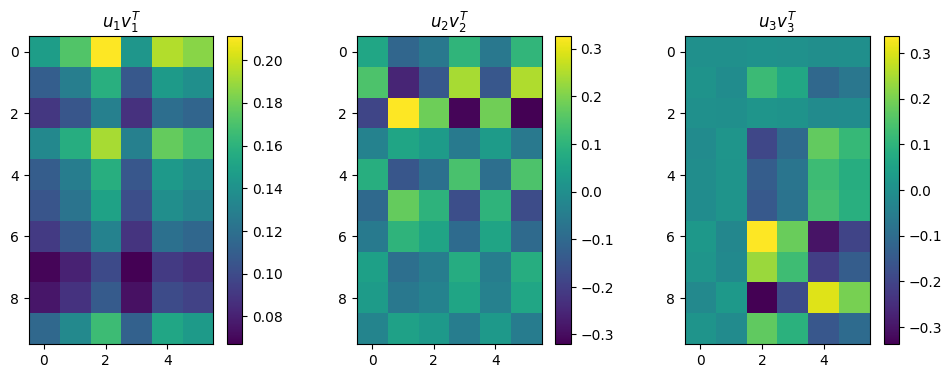

<Figure size 640x480 with 0 Axes>

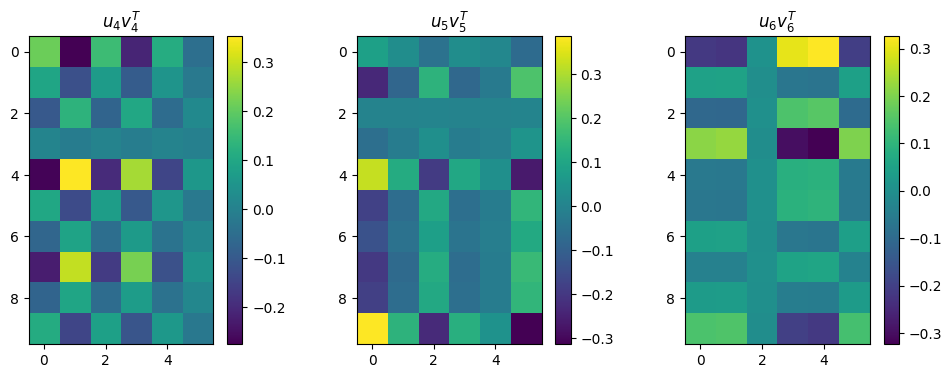

<Figure size 640x480 with 0 Axes>

<Figure size 1200x400 with 0 Axes>

The two matrices are equal up to a relative tolerance of 1e-13
Maximum absolute difference between two elements of the different matrices: 1.0547118733938987e-15


In [139]:
import numpy as np
import matplotlib.pyplot as plt

# Initialize the random number generator
rng = np.random.default_rng()

# Create a 10x6 matrix of random floats between 0 and 1
A = rng.random((10, 6))

# Get U, S and V^T matrices for matrix A
U, Sdiag, VT = np.linalg.svd(A, full_matrices=False)

# Define arrays containing the column vectors of U and row vectors of VT
u = np.zeros((6,10))
v_t = np.zeros((6,6))

for i in range (0,6,1):
    u[i] = U[:,i]
    v_t[i] = VT[i,:]


# Compute the sum
comp_matrices = np.zeros((6,10,6)) # matrix of component matrices

# Compute the outer product using the column vectors of U and row vectors of VT
for ind, u_i in enumerate(u):
    comp_matrices[ind] = np.outer(u_i, v_t[ind]) # compute outer product of U columns and V^T rows

# Visualize component matrices as a color map (code taken from the course notes on Laplace's equation)
def plot_matrices(A, titles=[], nmax=4):
    n = len(A)
    if titles==[]:
        titles = [""]*n
    if n>nmax:
        nx = nmax
    else:
        nx = n
    for j in range(int(np.floor(n/nmax))+1):        
        plt.clf()
        plt.figure(figsize=(nx*4,4))
        jmax = nmax*(j+1)
        if jmax > n:
            jmax = n
        for i,AA in enumerate(A[nmax*j:jmax]):
            plt.subplot(1, nx, i+1)
            plt.imshow(AA)
            plt.colorbar()
            plt.title(titles[nmax*j + i])
        plt.show()

# Plot color maps of the component matrices
titles = [f"$u_{1}v^T_{1}$", f"$u_{2}v^T_{2}$", f"$u_{3}v^T_{3}$", f"$u_{4}v^T_{4}$", f"$u_{5}v^T_{5}$", f"$u_{6}v^T_{6}$"]
plot_matrices(comp_matrices, titles=titles, nmax=3)

# Multiply each matrix by the associated singular value
for j, s in enumerate(Sdiag):
    comp_matrices[j] = s*comp_matrices[j]

# Compute the sum of the 6 matrices
sum_matrix = np.zeros((10,6))
for m in comp_matrices:
    sum_matrix = sum_matrix + m


# Check that the sum gives the original matrix
# The function "np.allclose" check whether two arrays are element-wise equal, within a specified tolerance
if np.allclose(A, sum_matrix, rtol=1e-13, atol=0):
    print("The two matrices are equal up to a relative tolerance of 1e-13")

# Get an idea of the error, by finding the largest difference between two elements of the matrices
error = np.max(np.abs(A-sum_matrix))
print("Maximum absolute difference between two elements of the different matrices:", error)

From the output above, we can indeed see that the sum in part a) gives the same result as the original matrix for $\mathbf{A}$. This was verified using two different methods. First, the numpy function "np.allclose", which checks whether two arrays/matrices are element-wise equal, within a specified relative and absolute tolerance, was used to compare the original matrix $\mathbf{A}$ with the matrix computed using the sum form, with a relative tolerance of $10^{-13}$ (and an absolute tolerance set to 0). The function returned "True" for every run (I ran the code multiple times, to make sure that it was always the case), meaning that the two matrices must agree within at least a relative tolerance of $10^{-13}$. On top of this, I also calculated the absolute value of the difference between the two matrices, and identified the largest resulting component in the difference matrix. Indeed, this is a measure of how much the two matrices vary in the worst case. Every time the code is run, the maximum absolute difference between two elements of the two matrices (analogous to the error) is of the order of $10^{-15}$ or $10^{-16}$. Therefore, this means that the two matrices are very close to being identical to the level of machine precision, meaning that they can be considered equal.

Also, one interesting thing to note is that for all component matrices $\mathbf{u_{\alpha}v^T_{\alpha}}$ except for the first one, there are actually multiple negative matrix components. This is fine for these individual matrices however, since the sum of all component matrices multiplied by their respective singular value still ends up giving positive values between 0 and 1, which falls in the range of values makiing up the matrix $\mathbf{A}$.

Part c)

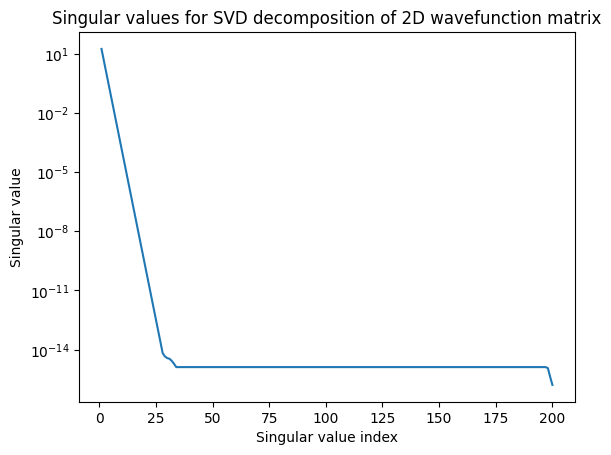

In [162]:
import numpy as np
import matplotlib.pyplot as plt

# 2D wavefuntion
def psi(x, y, alpha, C):
    exp = np.exp(-(x**2 + y**2 + alpha*x*y)/2)
    return C*exp

# Function to calculate the value of the 2D wavefunction at each point in a grid, and return the corresponding matrix
def psi_sols(pos_lim, nsteps, alpha, c):
    # Grid points
    x = np.linspace(-pos_lim,pos_lim,nsteps)
    y = np.linspace(-pos_lim,pos_lim,nsteps)

    A = np.zeros((nsteps, nsteps))

    # Calculate psi at each point on the grid
    for i, xval in enumerate(x):
        for j, yval in enumerate(y):
            A[i,j] = psi(xval, yval, alpha, c)
    return A

# Define parameters
alpha = 1
c = 1
    
h = 0.1 # different step values
pos_lim = 10 # last point in x and y on the grid
nsteps = int(2*pos_lim/h) # calculate number of steps

A = psi_sols(pos_lim, nsteps, alpha, c)

U_matrix, S_matrix, VT_matrix = np.linalg.svd(A, full_matrices=False) # singular value decomposition
s_val_ind = np.arange(1, nsteps+1, 1) # indices for the singular values

# Plotting the singular values
plt.plot(s_val_ind, S_matrix)
plt.yscale('log')
plt.xlabel("Singular value index")
plt.ylabel("Singular value")
plt.title("Singular values for SVD decomposition of 2D wavefunction matrix")
plt.show()

From the plot of the singular values above (using a log scale for the y axis to better visualize the order of magnitude of the singular values), we can tell that the singular values decrease rapidly between the 1st and 25th singular value, and afterwards remains at values of order $10^{-15}$ or $10^{-16}$. Therefore, we can see that the sum terms after the 25th term all have very minor contributions to the overall matrix $\mathbf{A}$.

Now, let's see how well the sum in part a) reproduces the wavefunction if we truncate the sum after different numbers of terms:

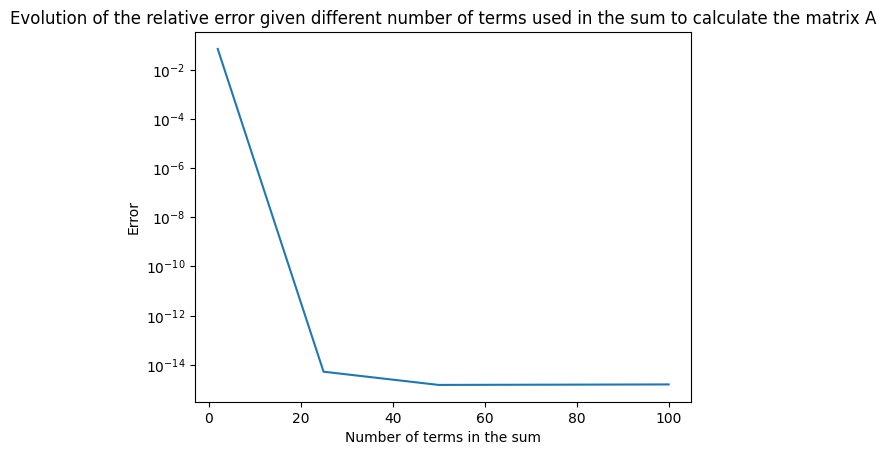

The relative error for the matrix obtained with the first 100 terms of the sum is 1.581215495327263e-15
The relative error for the matrix obtained with the first 75 terms of the sum is 1.545078254304604e-15
The relative error for the matrix obtained with the first 50 terms of the sum is 1.5097548391693619e-15
The relative error for the matrix obtained with the first 25 terms of the sum is 5.210891592453298e-15
The relative error for the matrix obtained with the first 10 terms of the sum is 1.9077634525997274e-06
The relative error for the matrix obtained with the first 5 terms of the sum is 0.0013812181046456518
The relative error for the matrix obtained with the first 2 terms of the sum is 0.07179676972449081


In [160]:
# Compute the sum (taken from part b), adapted for truncated sums)
def compute_sum(U, S, VT):
    # Define arrays containing the column vectors of U and row vectors of VT (only as many as needed given the truncated sum, therefore the reduced S matrix)
    u = np.zeros((len(S),len(U)))
    v_t = np.zeros((len(S),len(VT[0])))

    for i in range (0,len(S),1):
        u[i] = U[:,i]
        v_t[i] = VT[i,:]

    comp_matrices = np.zeros((len(S),len(U),len(VT[0]))) # matrix of component matrices

    # Compute the outer product using the column vectors of U and row vectors of VT
    for ind, u_i in enumerate(u):
        comp_matrices[ind] = np.outer(u_i, v_t[ind]) # compute outer product of U columns and V^T rows

    # Multiply each matrix by the associated singular value
    for j, s in enumerate(S):
        comp_matrices[j] = s*comp_matrices[j]

    # Compute the sum of the selected component matrices
    sum_matrix = np.zeros((len(U),len(VT[0])))
    # for m in comp_matrices:
    #     sum_matrix = sum_matrix + m
    for k in range(len(S)):
        sum_matrix = sum_matrix + comp_matrices[k]
    return sum_matrix

# Compute the sum using a truncated matrix for S (based on the number of terms wanted in the sum)
A_full = compute_sum(U_matrix, S_matrix, VT_matrix)
A_trunc1 = compute_sum(U_matrix, S_matrix[:100], VT_matrix)
A_trunc2 = compute_sum(U_matrix, S_matrix[:75], VT_matrix)
A_trunc3 = compute_sum(U_matrix, S_matrix[:50], VT_matrix)
A_trunc4 = compute_sum(U_matrix, S_matrix[:25], VT_matrix)
A_trunc5 = compute_sum(U_matrix, S_matrix[:10], VT_matrix)
A_trunc6 = compute_sum(U_matrix, S_matrix[:5], VT_matrix)
A_trunc7 = compute_sum(U_matrix, S_matrix[:2], VT_matrix)

# Compute relative error for each matrix obtained with truncated sums
num_terms = np.array([100, 75, 50, 25, 10, 5, 2]) # array of the number of terms in each computed sum
err = np.zeros(len(num_terms)) # array that will contain the error for wach sum
# err[0] = np.max(np.abs(A_full-A_trunc1))
# err[1] = np.max(np.abs(A_full-A_trunc2))
# err[2] = np.max(np.abs(A_full-A_trunc3))
# err[3] = np.max(np.abs(A_full-A_trunc4))
# err[4] = np.max(np.abs(A_full-A_trunc5))
# err[5] = np.max(np.abs(A_full-A_trunc6))
# err[6] = np.max(np.abs(A_full-A_trunc7))
err[0] = np.linalg.norm(A_trunc1-A)/np.linalg.norm(A)
err[1] = np.linalg.norm(A_trunc2-A)/np.linalg.norm(A)
err[2] = np.linalg.norm(A_trunc3-A)/np.linalg.norm(A)
err[3] = np.linalg.norm(A_trunc4-A)/np.linalg.norm(A)
err[4] = np.linalg.norm(A_trunc5-A)/np.linalg.norm(A)
err[5] = np.linalg.norm(A_trunc6-A)/np.linalg.norm(A)
err[6] = np.linalg.norm(A_trunc7-A)/np.linalg.norm(A)

# Plot the error as a function of number of steps in the sum
plt.plot(num_terms, err)
plt.yscale('log')
plt.xlabel("Number of terms in the sum")
plt.ylabel("Error")
plt.title("Evolution of the relative error given different number of terms used in the sum to calculate the matrix A")
plt.show()

# Print results
for index, error in enumerate(err):
    print(f"The relative error for the matrix obtained with the first {num_terms[index]} terms of the sum is {err[index]}")

From the results above, we can therefore tell that as we are decreasing the number of terms in the sum from 200 to 25 terms, the error does not change much, and is in fact negligeable because it is within floating point precision (which is consistent with what was observed for the size of the singular values past the 25th singular value). However, as we decrease the number of terms in the sum from 25 down to 2, we can see that the error starts to grow rapidly, reaching around 0.072 for only 2 terms in the sum. Therefore, we can see a correlation between the value of the singular values and importance of the terms in the reconstruction of $\mathbf{A}$ through the sum, given that smaller singular values are linked to more minor corrections, which do not have much of an effect on the error of the final computed matrix. It is to note that to calculate the relative error of the computed matrices, I calculated the relative error using the norm of the difference of the truncated sum matrix and the original wavefunction matrix $\mathbf{A}$, divided by the norm of the original matrix $\mathbf{A}$.

Part d)

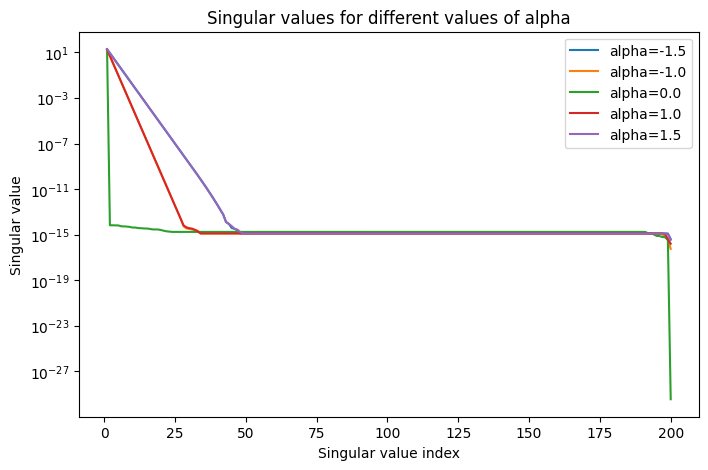

In [173]:
# Define parameters
alpha_vals = np.array([-1.5, -1, 0, 1, 1.5])
c = 1
    
h = 0.1 # different step values
pos_lim = 10 # last point in x and y on the grid
nsteps = int(2*pos_lim/h) # calculate number of steps

A = np.zeros((len(alpha_vals), nsteps, nsteps))

for i, alpha in enumerate(alpha_vals):
    A[i] = psi_sols(pos_lim, nsteps, alpha, c)

U_matrices = np.zeros((len(alpha_vals), nsteps, nsteps))
VT_matrices = np.zeros((len(alpha_vals), nsteps, nsteps))
S_matrices = np.zeros((len(alpha_vals), nsteps))

for ind, a_matrix in enumerate(A):
    U_matrices[ind], S_matrices[ind], VT_matrices[ind] = np.linalg.svd(a_matrix, full_matrices=False) # singular value decomposition

# Plot the singular values for each value of alpha
plt.figure(figsize=(8,5))

for j, alp in enumerate(alpha_vals):
    s_val_ind = np.arange(1, nsteps+1, 1) # indices for the singular values

    # Plotting the singular values
    plt.plot(s_val_ind, S_matrices[j], label=f"alpha={alp}")
    
plt.yscale('log')
plt.xlabel("Singular value index")
plt.ylabel("Singular value")
plt.title("Singular values for different values of alpha")
plt.legend()
plt.show()

In [176]:
# Print the 5 first singular values for the S matrix when alpha is 0
print(S_matrices[2][:5])

[1.76359158e+01 6.78075491e-15 6.71377260e-15 6.66774744e-15
 6.51251134e-15]


From this plot of the singular values given different values of alpha, we can clearly see a difference when it comes to at which point the singular values become very small (floating point precision scale). Indeed, as we saw above, for $\alpha = 1$, the singular values decrease rapidly up until the 25th singular value, after which they become on the order of $10^{-15}$ or $10^{-16}$. The same behaviour is observed for $\alpha = -1$. This decrease occurs more gradually for $\alpha = 1.5$, and singular values become of order $10^{-15}$ or $10^{-16}$ after around 50 terms (again, the same is observed for $\alpha = -1.5$). In contrast, for $\alpha = 0$, this decrease occurs way more abruptly, and singular values immediately drop to values of order $10^{-15}$ or $10^{-16}$ after a few terms (in the plot above, it almost appears as if the decrease has an infinite slope). Indeed, when printing the first 5 values of the S matrix when $\alpha = 0$, we can see that only the first singular value is of a significant size, whereas all other singular values are of the order of floating point precision (see above). Therefore, this shows us that when $\alpha = 0$, only the first singular value is significant. Given the results found in part c), we can also deduce that the errors will behave approximately the same, where they are negligeable if we consider all terms with significant singular values, and start to increase once we neglect some of the significant singular values after truncating $\mathbf{S}$.

This is the case because when $\alpha = 0$, our 2D wavefunction reduces to:

$$
\psi(x,y)=Ce^{-(x^2+y^2)/2}=Ce^{-x^2/2}e^{-y^2/2}
$$

From this, we can see that the wavefunction can be written as a product of two independent function (such as $f(x_i)g(y_j)$), and is therefore separable. Therefore, the $\mathbf{A}$ matrix of the 2D wavefunction executed at each grid point can be written as an outer product of two vectors containing the values of $f(x_i)$ and $g(y_j)$, meaning that it is of rank 1. As we saw in part a), the sum representation of $\mathbf{A}$ involves a sum of outer products of column and row vectors. Therefore, only one term in the SVD sum is required to express the reconstructed matrix of a separable function.

## Question 3 - Lorenz equations

Part a)

In [180]:
import numpy as np
import matplotlib.pyplot as plt

# Function that will return the final vector with all states for x, y and z
def lorenz(sigma, rho, beta, h, t_end):
    nsteps = int(t_end / h)

    # Initial conditions
    x = np.zeros(nsteps+1)
    y = np.zeros(nsteps+1)
    z = np.zeros(nsteps+1)

    x[0] = 1
    y[0] = 0
    z[0] = 0

    # Newton parameters
    tol = 1e-10
    max_iter = 10

    for n in range(nsteps):
        xyz = np.array([x[n], y[n], z[n]]) # 

        # Newton iterations
        for k in range(max_iter):
            xg, yg, zg = xyz # use last state as initial guess

            # Set up F and J matrices (matrix elements taken from the midterm solutions posted on the course website)
            F = np.array([xg-x[n]-h*sigma*(yg-xg), yg-y[n]-h*rho*xg+h*xg*zg+h*yg, zg-z[n]-h*xg*yg+h*beta*zg])
            J = np.array([[1+h*sigma, -h*sigma, 0], [-h*rho+h*zg, 1+h, h*xg], [-h*yg, -h*xg, 1+h*beta]])

            # Solve for our correction
            delta = np.linalg.solve(J, -F)
            xyz += delta # add correction to our initial guess for the next iteration (if required)

            # Check convergence
            if np.linalg.norm(delta) < tol:
                break
        
        # Store converged solution
        x[n+1] = xyz[0]
        y[n+1] = xyz[1]
        z[n+1] = xyz[2]
    return x, y, z

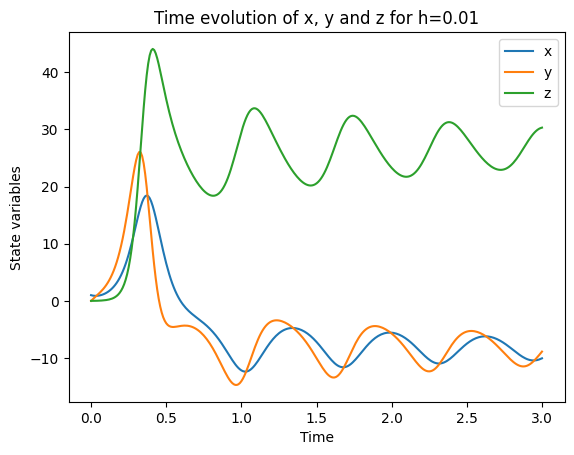

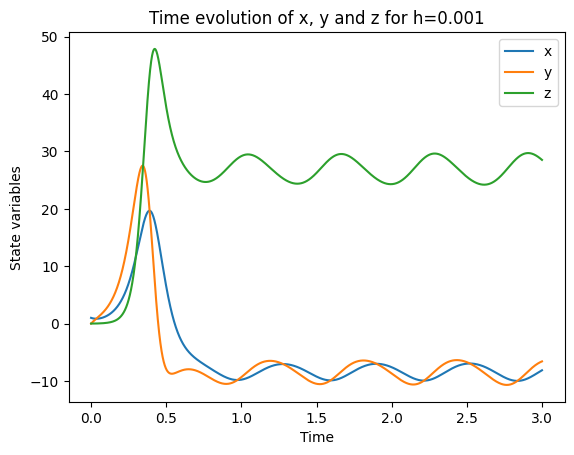

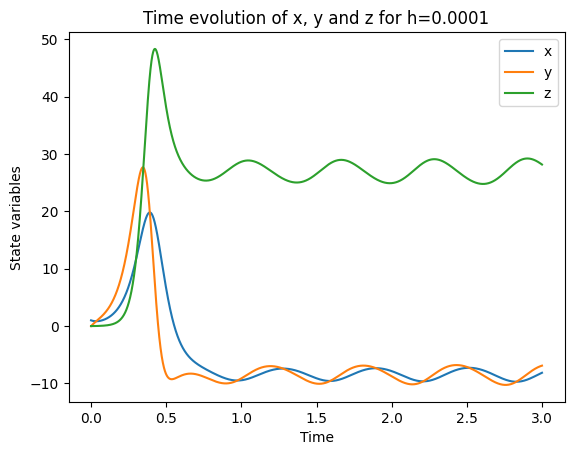

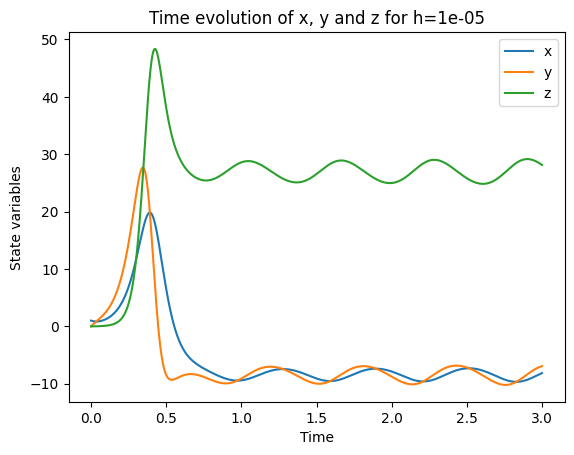

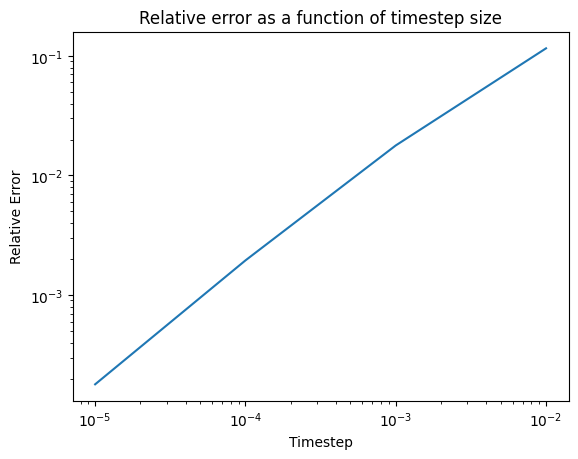

In [191]:
# Parameters (given in the problem)
sigma = 10
rho = 28
beta = 8/3

h_vals = [1e-2, 1e-3, 1e-4, 1e-5] # different timestep values
t_end = 3 # integration end time

# Array to store the final states of the solutions
sols = []
x_ref, y_ref, z_ref = lorenz(sigma, rho, beta, 1e-6, t_end)
ref_sol = (x_ref[-1], y_ref[-1], z_ref[-1])

# Plot the solution for each timestep value
for h in h_vals:
    x, y, z = lorenz(sigma, rho, beta, h, t_end)
    sols.append((x[-1],y[-1],z[-1])) # store final states of solution
    
    # Plotting
    nsteps = int(t_end/h)
    t = np.linspace(0, t_end, nsteps+1)
    
    plt.plot(t, x, label='x')
    plt.plot(t, y, label='y')
    plt.plot(t, z, label='z')
    plt.xlabel('Time')
    plt.ylabel('State variables')
    plt.title(f"Time evolution of x, y and z for h={h}")
    plt.legend()
    plt.show()

# Evaluate convergence
sols = np.array(sols)
# actual_val = sols[-1] # use the final state for the solution using the smallest timestep as the actual value
err = np.zeros(len(h_vals))

for i, sol in enumerate(sols):
    err[i] = np.linalg.norm(sol-ref_sol)/np.linalg.norm(ref_sol)

plt.loglog(h_vals, err) # plot for all except the h=10^-5 case, since it will have an error of 0
plt.xlabel('Timestep')
plt.ylabel('Relative Error')
plt.title('Relative error as a function of timestep size')
plt.show()


From the above plots, we can see that as we decrease the timestep size, the solutions for x(t), y(t) and z(t) seem to be approaching each other. Indeed, there is a noticeable difference between the first two plots, whereas the last two (for $h = 10^{-4}$ and $h = 10^{-5}$) seem very similar (meaning that we are approaching/reaching convergence). Therefore, visually, a timestep of around $h = 10^{-4}$ appears to be needed to get a converged solution, given that the solution does not seem to change significantly with smaller values of $h$. Looking at the error plot (where the relative error was calcualted by taking the norm of the difference between the final state of the current solution and the final state of the solution using a timestep of $h = 10^{-6}$, divided by the norm of the final state for the solution with $h = 10^{-6}$), we can see that the relative error decreases as the timestep decreases, which confirms that the numerical solutions are approaching the correct solution (in this case we are using the solution at $h = 10^{-6}$ as an estimate). The error seems to scale linearly with the timestep size, appears to have a slope of 1 on the log-log plot (see plot above). Therefore, the solution converges with the scaling with $h$ that I expected, given that backwards-Euler is a first order method (meaning that the global error scales as $O(h)$).

Part b)

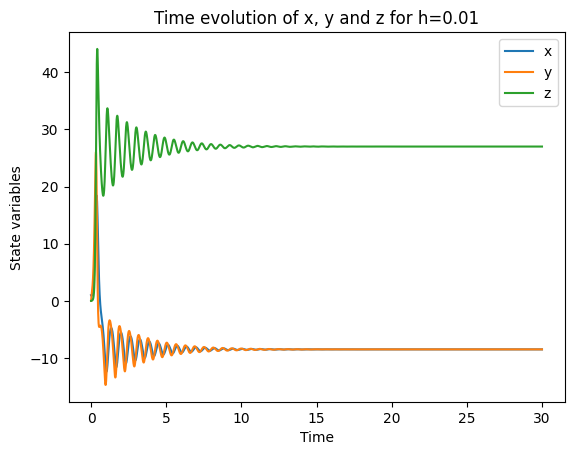

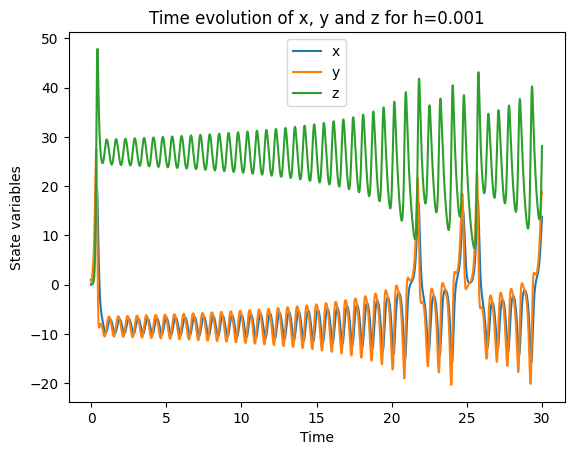

C:\Users\Élyse\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


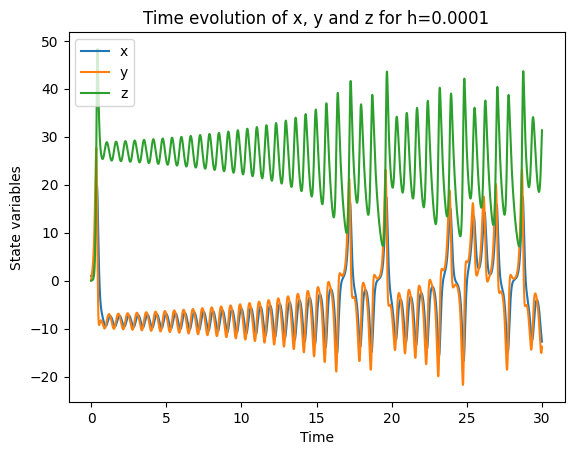

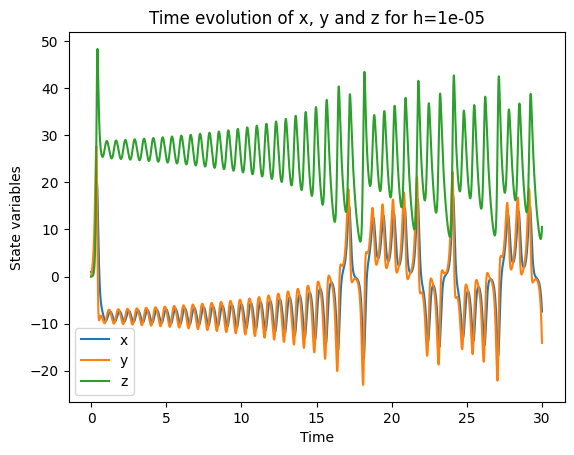

In [202]:
# Parameters
sigma = 10
rho = 28
beta = 8/3

h_vals = [1e-2, 1e-3, 1e-4, 1e-5] # timestep values
t_end = 30 # integration end time (using 30 instead of 3 now)

# Plot the solution for each timestep value
for h in h_vals:
    x, y, z = lorenz(sigma, rho, beta, h, t_end)
    
    # Plotting
    nsteps = int(t_end/h)
    t = np.linspace(0, t_end, nsteps+1)
    
    plt.plot(t, x, label='x')
    plt.plot(t, y, label='y')
    plt.plot(t, z, label='z')
    plt.xlabel('Time')
    plt.ylabel('State variables')
    plt.title(f"Time evolution of x, y and z for h={h}")
    plt.legend()
    plt.show()

From the plots above, I noticed that extending the integration time to $t = 30$ produces significantly different results depending on the timestep size, whereas when integrating to $t = 3$ the solutions approached each other as we decreased the timestep size. For $h = 10^{-2}$, the amplitude of the oscillations gradually decrease, and the solution approaches constant values. For smaller timesteps, such as $h = 10^{-3}$, $h = 10^{-4}$ and $h = 10^{-5}$, the solutions keep oscillating, and show irregular, chaotic behaviour. For all three of these smaller values, the solutions follow similar trajectories at first, but gradually diverge more and more as time passes (especially past t=15 for $h = 10^{-4}$ and $h = 10^{-5}$). This behaviour can be explained because the Lorenz system exhibits chaotic behaviour. Therefore, it is extremely sensitive to its starting conditions and small perturbations. Even though our initial conditions are the same, the different timestep sizes introduce different numerical errors that are amplified over time, causing the solutions to diverge.

Part c)

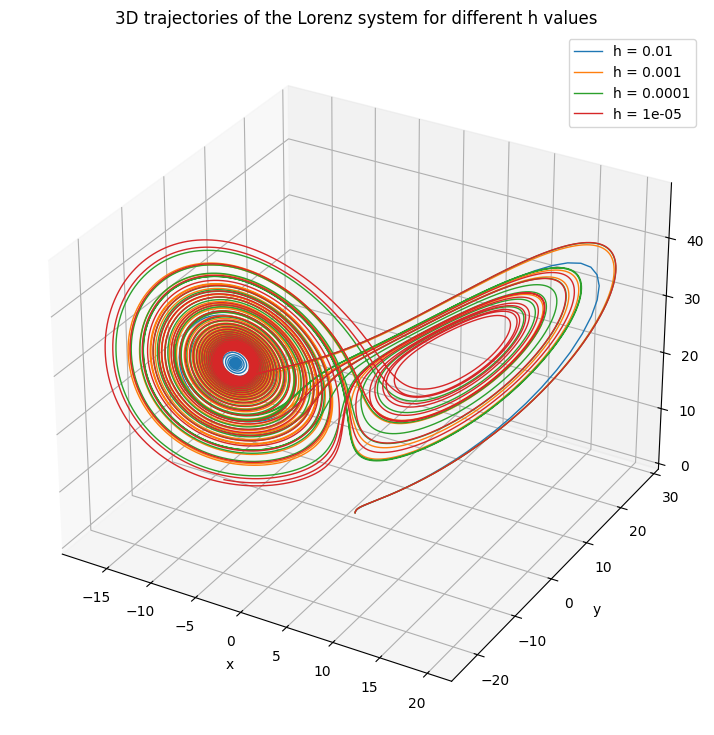

In [203]:
# Parameters
sigma = 10
rho = 28
beta = 8/3

h_vals = [1e-2, 1e-3, 1e-4, 1e-5] # different timestep values
t_end = 30 # integration end time

# Create 3D figure
fig = plt.figure(figsize=(12, 9))
ax1 = fig.add_subplot(111, projection='3d')

# Plot the solution for each timestep value
for h in h_vals:
    x, y, z = lorenz(sigma, rho, beta, h, t_end)

    ax1.plot(x, y, z, linewidth=1, label=f'h = {h}')
    

ax1.set_title("3D trajectories of the Lorenz system for different h values")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")
ax1.legend()

plt.show()

Although they diverge from one another, the trajectories for $h = 10^{-3}$, $h = 10^{-4}$ and $h = 10^{-5}$ trace out the same attractor! However, the trajectory for $h = 10^{-2}$ seems to spiral inward to a fixed point, instead of continuing along the trajectory of the butterfly-shaped attractor (which makes sense for what we observed in the plot of the time evolution for $h = 10^{-2}$ above, with the dampening of the oscillations). Since the detailed trajectories do not converge, we cannot directly compare them to evaluate numerical convergence. One strategy that could be used instead for this consists of checking statistical convergence, by comparing time-averaged quantities (such as time averages for x, y and z). If these quantities approach a constant value as we decrease the timestep, then we can conclude that we are approaching convergence even if the trajectories themselves differ.